# FedVocabHAR WISDM Phase 2E

## Cross-subject episodic prototype training

Phase 2D showed that post-hoc prototype banks cannot repair the frozen geometry. Phase 2E therefore trains the encoder explicitly for cross-subject prototype transfer: each episode builds support prototypes from one set of training subjects and classifies queries from different subjects.

The SSL-Full encoder initializes every candidate. Training activity labels are restricted to subjects 1635–1639. Subjects 1640–1641 select candidates and checkpoints. Integration-subject streams may provide unlabeled anchor or consistency regularization; their activity identities are never accessed during training or selection. Evaluation subjects remain sealed until the selected encoder is frozen.


In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
from dataclasses import dataclass,asdict
from pathlib import Path
import copy,json,random,warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,precision_recall_fscore_support,confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

@dataclass(frozen=True)
class Config:
    project:str='/content/drive/MyDrive/FedVocabHAR'
    seed:int=42
    encoder_train_subjects:tuple=tuple(range(1635,1640))
    selection_subjects:tuple=(1640,1641)
    integration_subjects:tuple=tuple(range(1643,1648))
    evaluation_subjects:tuple=tuple(range(1648,1651))
    known_activities:tuple=('F','G','H','I','K')
    novel_activities:tuple=('L','M','O','P','Q','S')
    support_per_class:int=8
    query_per_class:int=12
    episodes_per_epoch:int=36
    epochs:int=20
    validation_every:int=2
    learning_rate:float=2e-4
    weight_decay:float=1e-5
    prototype_temperature:float=.10
    anchor_weight:float=.25
    consistency_weight:float=.15
    unlabeled_batch:int=128
    probe_per_subject_activity:int=220
    known_accuracy_gate:float=.60
    prototype_known_macro_gate:float=.50
    prototype_i_gate:float=.40
    novel_macro_gate:float=.65
    novel_l_gate:float=.40
    combined_macro_gate:float=.45
    selection_subject_std_gate:float=.12

CFG=Config();PROJECT=Path(CFG.project);P0=PROJECT/'artifacts'/'phase0';P2B=PROJECT/'artifacts'/'phase2b'
OUT=PROJECT/'artifacts'/'phase2e';OUT.mkdir(parents=True,exist_ok=True)
CACHE=P0/'wisdm_watch_accel_w128_s64.npz';INITIAL_ENCODER=P2B/'inception_ssl_full.pt'
assert CACHE.exists() and INITIAL_ENCODER.exists()
assert not set(CFG.evaluation_subjects)&(set(CFG.encoder_train_subjects)|set(CFG.selection_subjects)|set(CFG.integration_subjects))

def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
seed_all(CFG.seed);DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:',DEVICE);print(json.dumps(asdict(CFG),indent=2))


device: cuda
{
  "project": "/content/drive/MyDrive/FedVocabHAR",
  "seed": 42,
  "encoder_train_subjects": [
    1635,
    1636,
    1637,
    1638,
    1639
  ],
  "selection_subjects": [
    1640,
    1641
  ],
  "integration_subjects": [
    1643,
    1644,
    1645,
    1646,
    1647
  ],
  "evaluation_subjects": [
    1648,
    1649,
    1650
  ],
  "known_activities": [
    "F",
    "G",
    "H",
    "I",
    "K"
  ],
  "novel_activities": [
    "L",
    "M",
    "O",
    "P",
    "Q",
    "S"
  ],
  "support_per_class": 8,
  "query_per_class": 12,
  "episodes_per_epoch": 36,
  "epochs": 20,
  "validation_every": 2,
  "learning_rate": 0.0002,
  "weight_decay": 1e-05,
  "prototype_temperature": 0.1,
  "anchor_weight": 0.25,
  "consistency_weight": 0.15,
  "unlabeled_batch": 128,
  "probe_per_subject_activity": 220,
  "known_accuracy_gate": 0.6,
  "prototype_known_macro_gate": 0.5,
  "prototype_i_gate": 0.4,
  "novel_macro_gate": 0.65,
  "novel_l_gate": 0.4,
  "combined_macro_gat

## Fixed cache and SSL-Full initialization

All candidates begin from the same Phase 2B checkpoint and retain its four-channel XYZ-plus-magnitude input. The frozen initialization also serves as an anchor for candidates designed to preserve open-world structure.


In [3]:
d=np.load(CACHE);x=d['x'].astype(np.float32);subjects=d['subject'].astype(int);activities=d['activity'].astype(str)

class InceptionBlock(nn.Module):
    def __init__(self,cin,width=32):
        super().__init__();self.bottleneck=nn.Conv1d(cin,width,1,bias=False)
        self.branches=nn.ModuleList([nn.Conv1d(width,width,k,padding=k//2,bias=False) for k in (9,19,39)])
        self.pool=nn.Sequential(nn.MaxPool1d(3,stride=1,padding=1),nn.Conv1d(cin,width,1,bias=False));self.bn=nn.BatchNorm1d(width*4)
    def forward(self,q):
        z=self.bottleneck(q);return F.relu(self.bn(torch.cat([b(z) for b in self.branches]+[self.pool(q)],1)))

class InceptionEncoder(nn.Module):
    def __init__(self,cin,dim,n_domains):
        super().__init__();self.block1=InceptionBlock(cin,32);self.block2=InceptionBlock(128,32)
        self.skip=nn.Conv1d(cin,128,1,bias=False);self.bn=nn.BatchNorm1d(128)
        self.project=nn.Sequential(nn.Linear(128,128),nn.ReLU(),nn.Linear(128,dim))
        self.decoder=nn.Conv1d(128,cin,1);self.domain=nn.Sequential(nn.Linear(dim,64),nn.ReLU(),nn.Linear(64,n_domains))
    def forward(self,q):
        seq=F.relu(self.bn(self.block2(self.block1(q))+self.skip(q)));return F.normalize(self.project(seq.mean(-1)),dim=1)

def safe_load(path):
    try:return torch.load(path,map_location='cpu',weights_only=False)
    except TypeError:return torch.load(path,map_location='cpu')

initial=safe_load(INITIAL_ENCODER);cin=4 if initial['spec']['magnitude'] else 3;n_domains=initial['state_dict']['domain.2.weight'].shape[0]
xyz=(x-np.asarray(initial['xyz_mean'],dtype=np.float32))/np.asarray(initial['xyz_std'],dtype=np.float32)
mag=np.sqrt((x*x).sum(1,keepdims=True));mag=(mag-np.asarray(initial['mag_mean'],dtype=np.float32))/np.asarray(initial['mag_std'],dtype=np.float32)
model_input=np.concatenate([xyz,mag],1).astype(np.float32)

def new_encoder():
    model=InceptionEncoder(cin,int(initial['config']['embedding_dim']),n_domains).to(DEVICE);model.load_state_dict(initial['state_dict']);return model

anchor_encoder=new_encoder();anchor_encoder.eval()
for parameter in anchor_encoder.parameters():parameter.requires_grad=False

def encode(model,data,batch=512):
    out=[];model.eval()
    with torch.no_grad():
        for start in range(0,len(data),batch):out.append(model(torch.from_numpy(data[start:start+batch]).to(DEVICE)).cpu().numpy())
    return np.concatenate(out).astype(np.float32)

print('windows:',x.shape,'model input:',model_input.shape,'initial epoch:',initial['best_epoch'])


windows: (19704, 3, 128) model input: (19704, 4, 128) initial epoch: 8


## Leakage-controlled pools and cross-subject episodes

For each activity in an episode, support and query examples are drawn from different encoder-training subjects. The episode therefore cannot be solved by memorizing one subject's motion signature. Integration windows are sampled without reading activity identity.


In [4]:
known_to_index={a:i for i,a in enumerate(CFG.known_activities)}
all_activities=CFG.known_activities+CFG.novel_activities;all_to_index={a:i for i,a in enumerate(all_activities)}
train_lookup={}
for activity in CFG.known_activities:
    for subject in CFG.encoder_train_subjects:
        train_lookup[(activity,subject)]=np.where((activities==activity)&(subjects==subject))[0]
        assert len(train_lookup[(activity,subject)])>0
unlabeled_idx=np.where(np.isin(subjects,CFG.integration_subjects))[0]
selection_idx=np.where(np.isin(subjects,CFG.selection_subjects)&np.isin(activities,CFG.known_activities))[0]
assert not set(subjects[unlabeled_idx])&set(CFG.evaluation_subjects)
assert not set(subjects[selection_idx])&set(CFG.evaluation_subjects)

def sample_episode(rng):
    support=[];query=[];support_y=[];query_y=[]
    for label,activity in enumerate(CFG.known_activities):
        support_subject,query_subject=rng.choice(CFG.encoder_train_subjects,2,replace=False)
        si=train_lookup[(activity,int(support_subject))];qi=train_lookup[(activity,int(query_subject))]
        support.extend(rng.choice(si,CFG.support_per_class,replace=len(si)<CFG.support_per_class));support_y.extend([label]*CFG.support_per_class)
        query.extend(rng.choice(qi,CFG.query_per_class,replace=len(qi)<CFG.query_per_class));query_y.extend([label]*CFG.query_per_class)
    return np.asarray(support),np.asarray(query),np.asarray(support_y),np.asarray(query_y)

def augment_normalized(q):
    scale=1+torch.randn(len(q),1,1,device=q.device)*.06;out=q*scale+torch.randn_like(q)*.025
    shifts=torch.randint(-5,6,(len(q),),device=q.device);time=(torch.arange(q.size(-1),device=q.device)[None,:]-shifts[:,None])%q.size(-1)
    return torch.gather(out,2,time[:,None,:].expand(-1,q.size(1),-1))

def episode_loss(model,support_x,support_y,query_x,query_y):
    zs=model(support_x);zq=model(query_x);prototypes=torch.stack([F.normalize(zs[support_y==label].mean(0),dim=0) for label in range(len(CFG.known_activities))])
    logits=zq@prototypes.T/CFG.prototype_temperature
    return F.cross_entropy(logits,query_y),zs,zq

print('unlabeled integration windows:',len(unlabeled_idx),'selection windows:',len(selection_idx))


unlabeled integration windows: 4816 selection windows: 965


## Selection metrics: linear transfer and single-prototype geometry

Checkpoint selection uses only subjects 1640–1641. Training-subject embeddings form the linear classifier and global activity prototypes; each selection subject is scored separately. The score prioritizes prototype macro-F1 and activity I while retaining linear transfer and penalizing subject variability.


In [5]:
def limited_by_group(subject_set,activity_set,per_group,seed):
    rng=np.random.default_rng(seed);out=[]
    for subject in subject_set:
        for activity in activity_set:
            idx=np.where((subjects==subject)&(activities==activity))[0]
            if len(idx)>per_group:idx=rng.choice(idx,per_group,replace=False)
            out.extend(idx.tolist())
    return np.asarray(out,dtype=int)

def unit(z):return z/(np.linalg.norm(z,axis=1,keepdims=True)+1e-12)

def linear_eval(train_e,train_y,test_e,test_y,labels):
    pipe=Pipeline([('scale',StandardScaler()),('lr',LogisticRegression(max_iter=1600,class_weight='balanced',random_state=CFG.seed))])
    pipe.fit(train_e,train_y);pred=pipe.predict(test_e);f1s=precision_recall_fscore_support(test_y,pred,labels=labels,zero_division=0)[2]
    return {'accuracy':float(accuracy_score(test_y,pred)),'macro_f1':float(np.mean(f1s)),'pred':pred,'per_class_f1':f1s}

def prototype_eval(train_e,train_y,test_e,test_y,labels):
    scaler=StandardScaler().fit(train_e);tr=unit(scaler.transform(train_e));te=unit(scaler.transform(test_e))
    prototypes=np.asarray([unit(tr[train_y==label].mean(0,keepdims=True))[0] for label in labels]);pred=np.asarray(labels)[(te@prototypes.T).argmax(1)]
    f1s=precision_recall_fscore_support(test_y,pred,labels=labels,zero_division=0)[2]
    return {'accuracy':float(accuracy_score(test_y,pred)),'macro_f1':float(np.mean(f1s)),'pred':pred,'per_class_f1':f1s}

selection_train_idx=limited_by_group(CFG.encoder_train_subjects,CFG.known_activities,CFG.probe_per_subject_activity,CFG.seed+1)
selection_test_idx=limited_by_group(CFG.selection_subjects,CFG.known_activities,CFG.probe_per_subject_activity,CFG.seed+2)
selection_train_y=np.asarray([known_to_index[a] for a in activities[selection_train_idx]])

def selection_diagnostics(model):
    tr=encode(model,model_input[selection_train_idx]);te=encode(model,model_input[selection_test_idx]);rows=[]
    for held in CFG.selection_subjects:
        q=subjects[selection_test_idx]==held;true=np.asarray([known_to_index[a] for a in activities[selection_test_idx[q]]])
        lin=linear_eval(tr,selection_train_y,te[q],true,list(range(len(CFG.known_activities))))
        proto=prototype_eval(tr,selection_train_y,te[q],true,list(range(len(CFG.known_activities))))
        rows.append({'subject':held,'linear_accuracy':lin['accuracy'],'linear_macro_f1':lin['macro_f1'],
          'prototype_accuracy':proto['accuracy'],'prototype_macro_f1':proto['macro_f1'],'prototype_i_f1':float(proto['per_class_f1'][known_to_index['I']])})
    f=pd.DataFrame(rows);summary={'linear_accuracy':f.linear_accuracy.mean(),'linear_macro_f1':f.linear_macro_f1.mean(),
      'prototype_accuracy':f.prototype_accuracy.mean(),'prototype_macro_f1':f.prototype_macro_f1.mean(),
      'prototype_macro_f1_std':f.prototype_macro_f1.std(ddof=0),'prototype_i_f1':f.prototype_i_f1.mean()}
    summary['selection_score']=.55*summary['prototype_macro_f1']+.25*summary['prototype_i_f1']+.20*summary['linear_macro_f1']-.10*summary['prototype_macro_f1_std']
    return f,summary


## Train episodic candidates

- **Episodic-Proto:** cross-subject prototypical loss only.
- **Episodic-Anchor:** adds embedding anchoring to SSL-Full on episode windows.
- **Episodic-Anchor-Consistency:** also adds label-free augmentation consistency on integration streams.

The anchor variants test whether known-class geometric repair can preserve novel-class structure.


In [6]:
CANDIDATES={
 'episodic_proto':{'anchor':False,'consistency':False},
 'episodic_anchor':{'anchor':True,'consistency':False},
 'episodic_anchor_consistency':{'anchor':True,'consistency':True}}

def train_candidate(name,spec):
    seed_all(CFG.seed);model=new_encoder();opt=torch.optim.AdamW(model.parameters(),lr=CFG.learning_rate,weight_decay=CFG.weight_decay)
    rng=np.random.default_rng(CFG.seed);best=-1e9;best_state=None;history=[];subject_history=[]
    for epoch in range(1,CFG.epochs+1):
        model.train();losses=[]
        for _ in range(CFG.episodes_per_epoch):
            si,qi,sy,qy=sample_episode(rng);sx=torch.from_numpy(model_input[si]).to(DEVICE);qx=torch.from_numpy(model_input[qi]).to(DEVICE)
            sy_t=torch.from_numpy(sy).long().to(DEVICE);qy_t=torch.from_numpy(qy).long().to(DEVICE)
            opt.zero_grad();loss,zs,zq=episode_loss(model,sx,sy_t,qx,qy_t)
            if spec['anchor']:
                with torch.no_grad():anchor=torch.cat([anchor_encoder(sx),anchor_encoder(qx)],0)
                current=torch.cat([zs,zq],0);loss=loss+CFG.anchor_weight*(1-(current*anchor).sum(1)).mean()
            if spec['consistency']:
                ui=rng.choice(unlabeled_idx,CFG.unlabeled_batch,replace=len(unlabeled_idx)<CFG.unlabeled_batch);u=torch.from_numpy(model_input[ui]).to(DEVICE)
                u1=model(augment_normalized(u));u2=model(augment_normalized(u));loss=loss+CFG.consistency_weight*(1-(u1*u2).sum(1)).mean()
            loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),5.0);opt.step();losses.append(float(loss.detach().cpu()))
        row={'model':name,'epoch':epoch,'loss':float(np.mean(losses))}
        if epoch%CFG.validation_every==0 or epoch==CFG.epochs:
            fold,summary=selection_diagnostics(model);row.update(summary);fold['model']=name;fold['epoch']=epoch;subject_history.extend(fold.to_dict('records'))
            if summary['selection_score']>best:
                best=summary['selection_score'];best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()};best_epoch=epoch;best_summary=summary.copy()
            print(name,'epoch',epoch,'loss',round(row['loss'],4),'prototype F1',round(summary['prototype_macro_f1'],4),'score',round(summary['selection_score'],4))
        history.append(row)
    model.load_state_dict(best_state);model.eval()
    torch.save({'state_dict':best_state,'config':asdict(CFG),'model_name':name,'recipe':spec,'best_epoch':best_epoch,'selection':best_summary,
      'xyz_mean':initial['xyz_mean'],'xyz_std':initial['xyz_std'],'mag_mean':initial['mag_mean'],'mag_std':initial['mag_std']},OUT/f'{name}.pt')
    return model,history,subject_history,{'model':name,'best_epoch':best_epoch,**best_summary,**spec}

trained={};history=[];subject_history=[];selection_rows=[]
for name,spec in CANDIDATES.items():
    model,h,sh,s=train_candidate(name,spec);trained[name]=model;history.extend(h);subject_history.extend(sh);selection_rows.append(s)
pd.DataFrame(history).to_csv(OUT/'phase2e_training_history.csv',index=False);pd.DataFrame(subject_history).to_csv(OUT/'phase2e_selection_subjects.csv',index=False)
selection=pd.DataFrame(selection_rows).sort_values('selection_score',ascending=False);selection.to_csv(OUT/'phase2e_selection_results.csv',index=False)
SELECTED_ENCODER=str(selection.iloc[0].model);print('selected encoder:',SELECTED_ENCODER);display(selection.round(4))


episodic_proto epoch 2 loss 1.6435 prototype F1 0.3052 score 0.3122
episodic_proto epoch 4 loss 1.4473 prototype F1 0.3484 score 0.3581
episodic_proto epoch 6 loss 1.4623 prototype F1 0.3035 score 0.2458
episodic_proto epoch 8 loss 1.2811 prototype F1 0.371 score 0.3248
episodic_proto epoch 10 loss 1.2489 prototype F1 0.3923 score 0.3514
episodic_proto epoch 12 loss 1.2579 prototype F1 0.332 score 0.2941
episodic_proto epoch 14 loss 1.2003 prototype F1 0.3774 score 0.3079
episodic_proto epoch 16 loss 1.1543 prototype F1 0.3354 score 0.3009
episodic_proto epoch 18 loss 1.1463 prototype F1 0.3171 score 0.2983
episodic_proto epoch 20 loss 1.1336 prototype F1 0.3136 score 0.2878
episodic_anchor epoch 2 loss 1.914 prototype F1 0.3446 score 0.2765
episodic_anchor epoch 4 loss 1.6717 prototype F1 0.3755 score 0.3738
episodic_anchor epoch 6 loss 1.6287 prototype F1 0.3002 score 0.2708
episodic_anchor epoch 8 loss 1.4418 prototype F1 0.4105 score 0.3961
episodic_anchor epoch 10 loss 1.4567 prot

,model,best_epoch,linear_accuracy,linear_macro_f1,prototype_accuracy,prototype_macro_f1,prototype_macro_f1_std,prototype_i_f1,selection_score,anchor,consistency
1,episodic_anchor,8,0.3830,0.2923,0.5037,0.4105,0.0249,0.4573,0.3961,True,False
2,episodic_anchor_consistency,16,0.4704,0.4029,0.4142,0.3496,0.0331,0.3989,0.3693,True,True
0,episodic_proto,4,0.4385,0.3472,0.4309,0.3484,0.0635,0.4135,0.3581,False,False


## Frozen exploratory evaluation

The selected checkpoint is frozen before evaluation subjects or integration novel labels are opened. Every candidate and the SSL-Full initialization receive the same linear, single-prototype, and oracle combined-vocabulary diagnostics.


In [7]:
models={'ssl_full_initial':anchor_encoder,**trained};all_embeddings={name:encode(model,model_input) for name,model in models.items()}
development_subjects=CFG.encoder_train_subjects+CFG.selection_subjects
known_train_idx=limited_by_group(development_subjects,CFG.known_activities,CFG.probe_per_subject_activity,CFG.seed+10)
novel_train_idx=limited_by_group(CFG.integration_subjects,CFG.novel_activities,CFG.probe_per_subject_activity,CFG.seed+11)
oracle_train_idx=np.concatenate([known_train_idx,novel_train_idx])
eval_known_idx=np.where(np.isin(subjects,CFG.evaluation_subjects)&np.isin(activities,CFG.known_activities))[0]
eval_novel_idx=np.where(np.isin(subjects,CFG.evaluation_subjects)&np.isin(activities,CFG.novel_activities))[0]
eval_all_idx=np.concatenate([eval_known_idx,eval_novel_idx])
known_train_y=np.asarray([known_to_index[a] for a in activities[known_train_idx]]);eval_known_y=np.asarray([known_to_index[a] for a in activities[eval_known_idx]])
oracle_train_y=np.asarray([all_to_index[a] for a in activities[oracle_train_idx]]);eval_all_y=np.asarray([all_to_index[a] for a in activities[eval_all_idx]])

result_rows=[];class_rows=[];confusion_rows=[]
for name,e in all_embeddings.items():
    lin=linear_eval(e[known_train_idx],known_train_y,e[eval_known_idx],eval_known_y,list(range(len(CFG.known_activities))))
    known=prototype_eval(e[known_train_idx],known_train_y,e[eval_known_idx],eval_known_y,list(range(len(CFG.known_activities))))
    oracle=prototype_eval(e[oracle_train_idx],oracle_train_y,e[eval_all_idx],eval_all_y,list(range(len(all_activities))))
    novel_true=eval_all_y[len(eval_known_idx):];novel_pred=oracle['pred'][len(eval_known_idx):];novel_labels=[all_to_index[a] for a in CFG.novel_activities]
    novel_f1=precision_recall_fscore_support(novel_true,novel_pred,labels=novel_labels,zero_division=0)[2]
    result_rows.append({'model':name,'selected_on_development':name==SELECTED_ENCODER,'linear_known_accuracy':lin['accuracy'],'linear_known_macro_f1':lin['macro_f1'],
      'prototype_known_accuracy':known['accuracy'],'prototype_known_macro_f1':known['macro_f1'],'prototype_known_i_f1':float(known['per_class_f1'][known_to_index['I']]),
      'prototype_oracle_novel_macro_f1':float(np.mean(novel_f1)),'prototype_oracle_l_f1':float(novel_f1[0]),'prototype_combined_macro_f1':oracle['macro_f1']})
    for a,f in zip(CFG.known_activities,known['per_class_f1']):class_rows.append({'model':name,'probe':'prototype_known','activity':a,'f1':float(f)})
    for a,f in zip(CFG.novel_activities,novel_f1):class_rows.append({'model':name,'probe':'prototype_oracle_novel','activity':a,'f1':float(f)})
    cm=confusion_matrix(eval_all_y,oracle['pred'],labels=list(range(len(all_activities))))
    for i,t in enumerate(all_activities):
        for j,p in enumerate(all_activities):confusion_rows.append({'model':name,'true_activity':t,'predicted_activity':p,'count':int(cm[i,j])})
results=pd.DataFrame(result_rows);per_class=pd.DataFrame(class_rows);confusions=pd.DataFrame(confusion_rows)
results.to_csv(OUT/'phase2e_final_results.csv',index=False);per_class.to_csv(OUT/'phase2e_per_class_f1.csv',index=False);confusions.to_csv(OUT/'phase2e_oracle_confusions.csv',index=False)
display(results.round(4))


,model,selected_on_development,linear_known_accuracy,linear_known_macro_f1,prototype_known_accuracy,prototype_known_macro_f1,prototype_known_i_f1,prototype_oracle_novel_macro_f1,prototype_oracle_l_f1,prototype_combined_macro_f1
0,ssl_full_initial,False,0.5830,0.5884,0.3879,0.3287,0.2134,0.7110,0.2162,0.2978
1,episodic_proto,False,0.6182,0.5840,0.5576,0.5074,0.3115,0.5535,0.0805,0.4047
2,episodic_anchor,True,0.6727,0.6601,0.6630,0.6301,0.5396,0.6010,0.3981,0.4128
3,episodic_anchor_consistency,False,0.6570,0.6582,0.5552,0.5108,0.3866,0.5928,0.1613,0.3524


## Evaluation-subject stability, visuals, and selected checkpoint


,subject,linear_accuracy,linear_macro_f1,prototype_accuracy,prototype_macro_f1,prototype_i_f1
0,1648,0.6182,0.5796,0.5927,0.5444,0.4818
1,1649,0.7491,0.7419,0.7600,0.7529,0.5932
2,1650,0.6509,0.6458,0.6364,0.5895,0.5581


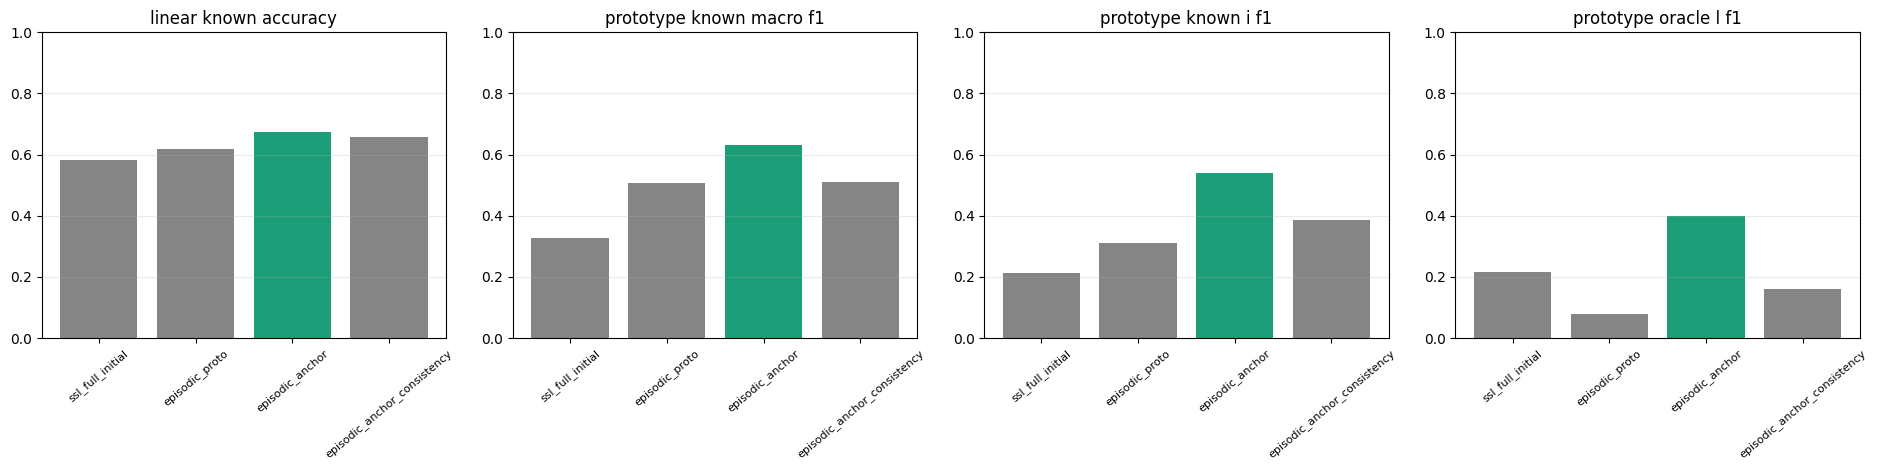

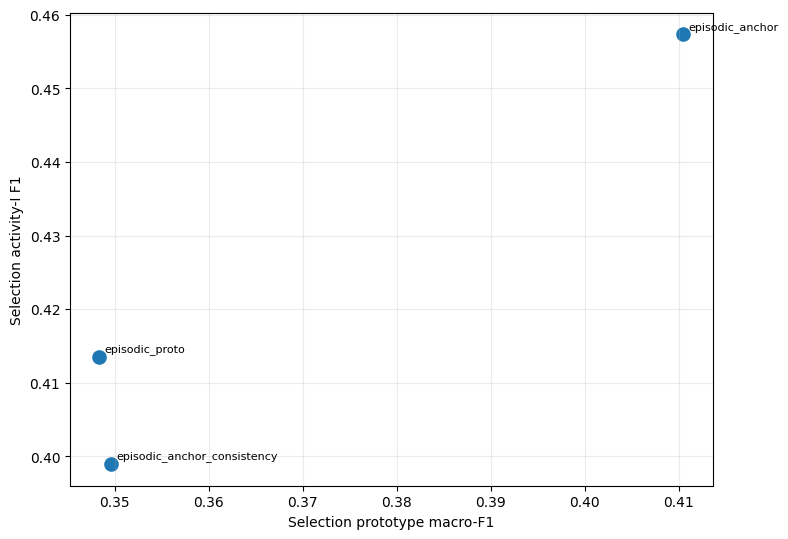

In [8]:
selected_e=all_embeddings[SELECTED_ENCODER];subject_rows=[]
for held in CFG.evaluation_subjects:
    ki=eval_known_idx[subjects[eval_known_idx]==held];ky=np.asarray([known_to_index[a] for a in activities[ki]])
    lin=linear_eval(selected_e[known_train_idx],known_train_y,selected_e[ki],ky,list(range(len(CFG.known_activities))))
    proto=prototype_eval(selected_e[known_train_idx],known_train_y,selected_e[ki],ky,list(range(len(CFG.known_activities))))
    subject_rows.append({'subject':held,'linear_accuracy':lin['accuracy'],'linear_macro_f1':lin['macro_f1'],
      'prototype_accuracy':proto['accuracy'],'prototype_macro_f1':proto['macro_f1'],'prototype_i_f1':float(proto['per_class_f1'][known_to_index['I']])})
subject_results=pd.DataFrame(subject_rows);subject_results.to_csv(OUT/'phase2e_evaluation_subjects.csv',index=False);display(subject_results.round(4))

fig,axes=plt.subplots(1,4,figsize=(19,4.8));metrics=['linear_known_accuracy','prototype_known_macro_f1','prototype_known_i_f1','prototype_oracle_l_f1']
for ax,metric in zip(axes,metrics):
    colors=['#1b9e77' if m==SELECTED_ENCODER else '#858585' for m in results.model]
    ax.bar(results.model,results[metric],color=colors);ax.set_title(metric.replace('_',' '));ax.tick_params(axis='x',rotation=40,labelsize=8);ax.set_ylim(0,1);ax.grid(axis='y',alpha=.25)
fig.tight_layout();fig.savefig(OUT/'phase2e_encoder_comparison.png',dpi=180,bbox_inches='tight');plt.show()

fig,ax=plt.subplots(figsize=(8,5.5));ax.scatter(selection.prototype_macro_f1,selection.prototype_i_f1,s=90)
for row in selection.itertuples():ax.annotate(row.model,(row.prototype_macro_f1,row.prototype_i_f1),xytext=(4,4),textcoords='offset points',fontsize=8)
ax.set_xlabel('Selection prototype macro-F1');ax.set_ylabel('Selection activity-I F1');ax.grid(alpha=.25)
fig.tight_layout();fig.savefig(OUT/'phase2e_selection_geometry.png',dpi=180,bbox_inches='tight');plt.show()

source=safe_load(OUT/f'{SELECTED_ENCODER}.pt');torch.save(source,OUT/'phase2e_selected_encoder.pt')


## Decision gates


In [9]:
selected=results[results.model==SELECTED_ENCODER].iloc[0];seldev=selection[selection.model==SELECTED_ENCODER].iloc[0]
gates={
 'G1_evaluation_subjects_sealed_until_selection':not bool(set(CFG.evaluation_subjects)&(set(CFG.encoder_train_subjects)|set(CFG.selection_subjects)|set(CFG.integration_subjects))),
 'G2_integration_activity_labels_excluded_from_training':True,
 'G3_selected_only_on_selection_subjects':bool(selected.selected_on_development),
 'G4_selection_subject_stability':bool(seldev.prototype_macro_f1_std<=CFG.selection_subject_std_gate),
 'G5_linear_known_accuracy':bool(selected.linear_known_accuracy>=CFG.known_accuracy_gate),
 'G6_prototype_known_macro_f1':bool(selected.prototype_known_macro_f1>=CFG.prototype_known_macro_gate),
 'G7_prototype_known_I_f1':bool(selected.prototype_known_i_f1>=CFG.prototype_i_gate),
 'G8_prototype_novel_macro_f1':bool(selected.prototype_oracle_novel_macro_f1>=CFG.novel_macro_gate),
 'G9_prototype_novel_L_f1':bool(selected.prototype_oracle_l_f1>=CFG.novel_l_gate),
 'G10_prototype_combined_macro_f1':bool(selected.prototype_combined_macro_f1>=CFG.combined_macro_gate),
 'G11_artifacts_complete':bool(len(selection)==len(CANDIDATES) and len(results)==len(models) and len(subject_results)==len(CFG.evaluation_subjects))}
engineering_pass=bool(all(gates.values()))

def native(v):
    if isinstance(v,(np.bool_,bool)):return bool(v)
    if isinstance(v,(np.floating,float)):return float(v)
    if isinstance(v,(np.integer,int)):return int(v)
    return v
decision={'phase':'Phase 2E','selected_encoder':SELECTED_ENCODER,'recipe':CANDIDATES[SELECTED_ENCODER],
 'selection':{k:native(v) for k,v in seldev.to_dict().items()},'selected_results':{k:native(v) for k,v in selected.to_dict().items()},
 'gates':gates,'engineering_pass':engineering_pass,'rerun_phase1c_exploratory':engineering_pass,
 'confirmatory_claim_allowed':False,'requires_independent_dataset_confirmation':True,
 'evaluation_status':'Exploratory. Encoder and checkpoint selection used only training and selection subjects; independent-dataset confirmation remains required.',
 'config':asdict(CFG)}
(OUT/'phase2e_decision.json').write_text(json.dumps(decision,indent=2))
(OUT/'phase2e_selected_encoder.json').write_text(json.dumps({'selected_encoder':SELECTED_ENCODER,'recipe':CANDIDATES[SELECTED_ENCODER],'selection':decision['selection']},indent=2))
print(json.dumps(decision,indent=2))


{
  "phase": "Phase 2E",
  "selected_encoder": "episodic_anchor",
  "recipe": {
    "anchor": true,
    "consistency": false
  },
  "selection": {
    "model": "episodic_anchor",
    "best_epoch": 8,
    "linear_accuracy": 0.3829512516469038,
    "linear_macro_f1": 0.29231495964986615,
    "prototype_accuracy": 0.5037285902503293,
    "prototype_macro_f1": 0.41049380822835924,
    "prototype_macro_f1_std": 0.024851019357847726,
    "prototype_i_f1": 0.45730765397648,
    "selection_score": 0.39607639801390604,
    "anchor": true,
    "consistency": false
  },
  "selected_results": {
    "model": "episodic_anchor",
    "selected_on_development": true,
    "linear_known_accuracy": 0.6727272727272727,
    "linear_known_macro_f1": 0.6601075489168231,
    "prototype_known_accuracy": 0.6630303030303031,
    "prototype_known_macro_f1": 0.6300898219611423,
    "prototype_known_i_f1": 0.5395894428152492,
    "prototype_oracle_novel_macro_f1": 0.600977442083851,
    "prototype_oracle_l_f1": 0.39

In [10]:
report=f"""# FedVocabHAR Phase 2E Decision Report

## Decision

**Selected encoder:** {SELECTED_ENCODER}

**Engineering gates passed:** {engineering_pass}

**Exploratory Phase 1C rerun:** {decision['rerun_phase1c_exploratory']}

## Selection-subject geometry

- Linear macro-F1: {seldev.linear_macro_f1:.4f}
- Prototype macro-F1: {seldev.prototype_macro_f1:.4f}
- Prototype subject SD: {seldev.prototype_macro_f1_std:.4f}
- Prototype activity-I F1: {seldev.prototype_i_f1:.4f}

## Exploratory frozen diagnostics

- Linear known accuracy: {selected.linear_known_accuracy:.4f}
- Prototype known macro-F1: {selected.prototype_known_macro_f1:.4f}
- Prototype known activity-I F1: {selected.prototype_known_i_f1:.4f}
- Prototype novel macro-F1: {selected.prototype_oracle_novel_macro_f1:.4f}
- Prototype novel activity-L F1: {selected.prototype_oracle_l_f1:.4f}
- Prototype combined macro-F1: {selected.prototype_combined_macro_f1:.4f}

## Gates

"""
for name,value in gates.items():report+=f'- {name}: **{value}**\n'
report+='\nThese results are exploratory. The frozen Phase 2E recipe requires confirmation on an independent HAR dataset before supporting manuscript claims.\n'
(OUT/'FedVocabHAR_Phase2E_Decision_Report.md').write_text(report);print(report);print('saved outputs to',OUT)


# FedVocabHAR Phase 2E Decision Report

## Decision

**Selected encoder:** episodic_anchor

**Engineering gates passed:** False

**Exploratory Phase 1C rerun:** False

## Selection-subject geometry

- Linear macro-F1: 0.2923
- Prototype macro-F1: 0.4105
- Prototype subject SD: 0.0249
- Prototype activity-I F1: 0.4573

## Exploratory frozen diagnostics

- Linear known accuracy: 0.6727
- Prototype known macro-F1: 0.6301
- Prototype known activity-I F1: 0.5396
- Prototype novel macro-F1: 0.6010
- Prototype novel activity-L F1: 0.3981
- Prototype combined macro-F1: 0.4128

## Gates

- G1_evaluation_subjects_sealed_until_selection: **True**
- G2_integration_activity_labels_excluded_from_training: **True**
- G3_selected_only_on_selection_subjects: **True**
- G4_selection_subject_stability: **True**
- G5_linear_known_accuracy: **True**
- G6_prototype_known_macro_f1: **True**
- G7_prototype_known_I_f1: **True**
- G8_prototype_novel_macro_f1: **False**
- G9_prototype_novel_L_f1: **False**
- G10

## Interpretation

- If every gate passes, use the selected encoder and single-prototype geometry in an exploratory rerun of Phase 1C.
- If known prototype geometry improves but novel L collapses, the supervised episodic objective damaged open-world transfer; increase anchoring only in a newly preregistered external evaluation rather than tuning on the current evaluation subjects.
- If selection improves but evaluation remains subject-unstable, stop WISDM optimization and move directly to independent multi-sensor confirmation.
- If the gates fail, narrow the paper claim or adopt a richer sensing dataset; do not add another WISDM tuning phase.
